# Input importance — leave-one-out retraining (full domain, 800×800)

Baseline = `full_domain_mask` (the full-domain model with the valid/building mask as an extra
spatial channel, 1 = air, 0 = building). Each physical input is removed (its *t* and *t−1*
channels zeroed) and the model is **retrained from scratch** (300 epochs, no early stopping,
same seed), then compared to the baseline — measuring *irreplaceability*: whether the
remaining inputs can compensate.

`valid mask` is one of the inputs under test; removing it is the model without the mask
channel, so its row quantifies how much the explicit mask adds. `(drop t-1)` zeroes the entire
previous-hour block; `height enc.` blanks the model's per-level height encoding.

Metrics: pooled RMSE (z0–11, physical µg/m³) and pattern correlation *r*, plus **per-layer**
RMSE and *r*, on valid cells only. Data: `outputs/input_ablation/input_importance_layer_mask.json`.
Noise floor ≈ ±0.01 RMSE.

## Part A — overall importance (pooled RMSE and r)

In [1]:
import json, numpy as np, matplotlib.pyplot as plt
D=json.load(open('../../outputs/input_ablation/input_importance_layer_mask.json'))
ZH=[15,25,35,45,55,75,95,115,135,155,175,195]
LAB={'no_mask':'valid mask','no_pm25bnd':'PM2.5 boundary','no_em':'emission','no_v':'v wind','no_u':'u wind',
     'no_qv':'qv','no_hour':'hour enc.','no_sp':'pressure','no_pt':'pt','no_height':'height enc.',
     't_only':'(drop t-1)'}
ORDER=['no_mask','no_pm25bnd','no_em','no_v','no_u','no_qv','no_hour','no_sp','no_pt','no_height','t_only']
b=D['base']['pooled']
print(f'baseline (all inputs + mask): RMSE {b["rmse"]:.3f}   r {b["r"]:.3f}\n')
print(f'{"input removed":>16} {"RMSE":>7} {"dRMSE":>8} {"%":>7} {"r":>7} {"dr":>8}')
print("-"*58)
for k in ORDER:
    m=D[k]['pooled']
    print(f'{LAB[k]:>16} {m["rmse"]:>7.3f} {m["rmse"]-b["rmse"]:>+8.3f} {100*(m["rmse"]-b["rmse"])/b["rmse"]:>+6.1f}% {m["r"]:>7.3f} {m["r"]-b["r"]:>+8.3f}')

# Figure font consistent with main text (Times New Roman; Liberation Serif is a
# metric-compatible fallback when Times New Roman is not installed).
import matplotlib as _mpl
_mpl.rcParams.update({'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'Nimbus Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix', 'axes.unicode_minus': False, 'font.size': 12})

baseline (all inputs + mask): RMSE 0.729   r 0.889

   input removed    RMSE    dRMSE       %       r       dr
----------------------------------------------------------
      valid mask   0.755   +0.027   +3.7%   0.887   -0.002
  PM2.5 boundary   1.796   +1.067 +146.4%   0.860   -0.029
        emission   0.840   +0.111  +15.3%   0.872   -0.017
          v wind   0.873   +0.144  +19.8%   0.793   -0.096
          u wind   0.822   +0.093  +12.8%   0.832   -0.057
              qv   0.826   +0.097  +13.3%   0.875   -0.014
       hour enc.   0.897   +0.169  +23.1%   0.863   -0.025
        pressure   0.815   +0.086  +11.8%   0.891   +0.002
              pt   0.722   -0.007   -0.9%   0.873   -0.016
     height enc.   0.778   +0.049   +6.7%   0.884   -0.005
      (drop t-1)   0.875   +0.147  +20.1%   0.874   -0.015


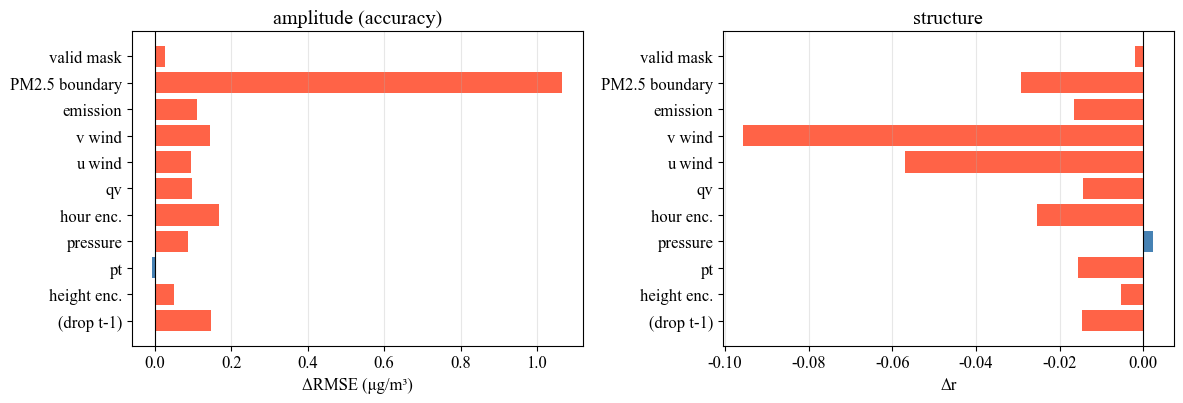

In [2]:
fig,axes=plt.subplots(1,2,figsize=(12,4.2))
names=[LAB[k] for k in ORDER]
dr=[D[k]['pooled']['rmse']-b['rmse'] for k in ORDER]
dp=[D[k]['pooled']['r']-b['r'] for k in ORDER]
axes[0].barh(names[::-1],dr[::-1],color=['tomato' if v>0 else 'steelblue' for v in dr[::-1]])
axes[0].set_xlabel('ΔRMSE (μg/m³)'); axes[0].set_title('amplitude (accuracy)')
axes[1].barh(names[::-1],dp[::-1],color=['tomato' if v<0 else 'steelblue' for v in dp[::-1]])
axes[1].set_xlabel('Δr'); axes[1].set_title('structure')
for ax in axes: ax.axvline(0,color='k',lw=0.8); ax.grid(True,alpha=0.3,axis='x')
plt.tight_layout(); plt.show()

## Part B — per-layer importance (where each input matters)

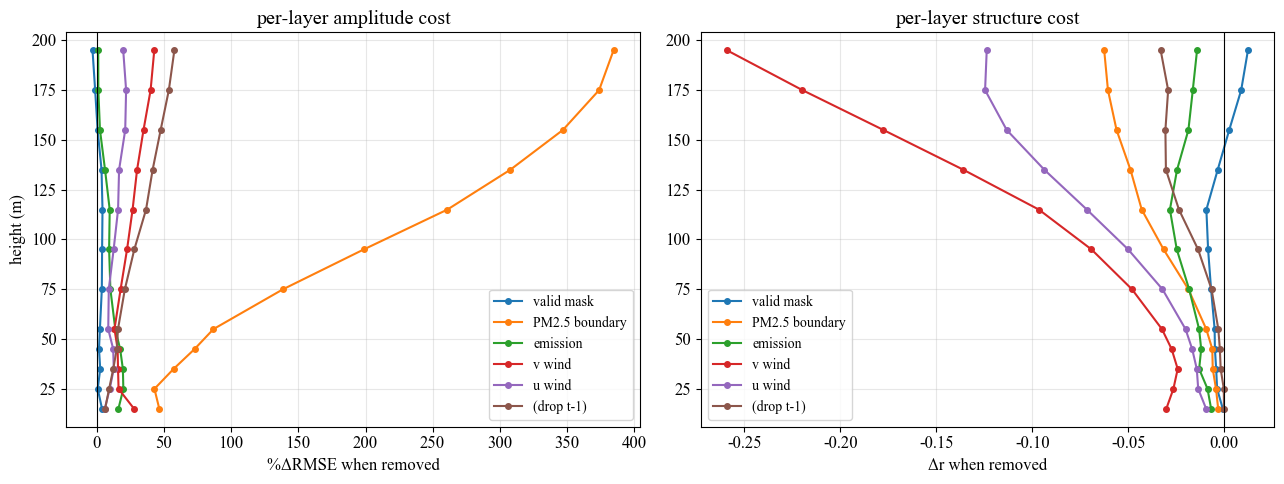

In [3]:
# per-layer ΔRMSE (% of baseline) and Δr, for the strongest inputs (+ the mask)
SHOW=['no_mask','no_pm25bnd','no_em','no_v','no_u','t_only']
fig,axes=plt.subplots(1,2,figsize=(13,5))
for k in SHOW:
    pdr=[100*(D[k]['layer'][str(z)]['rmse']-D['base']['layer'][str(z)]['rmse'])/D['base']['layer'][str(z)]['rmse'] for z in range(12)]
    dpp=[D[k]['layer'][str(z)]['r']-D['base']['layer'][str(z)]['r'] for z in range(12)]
    axes[0].plot(pdr,ZH,'o-',label=LAB[k],ms=4)
    axes[1].plot(dpp,ZH,'o-',label=LAB[k],ms=4)
axes[0].set_xlabel('%ΔRMSE when removed'); axes[0].set_ylabel('height (m)'); axes[0].set_title('per-layer amplitude cost')
axes[1].set_xlabel('Δr when removed'); axes[1].set_title('per-layer structure cost')
for ax in axes: ax.axvline(0,color='k',lw=0.8); ax.grid(True,alpha=0.3); ax.legend(fontsize=10)
plt.tight_layout(); plt.show()

In [4]:
# full per-layer matrix — every input (cols) × every layer (rows)
SHORT={'no_mask':'mask','no_pm25bnd':'bnd','no_em':'em','no_v':'v','no_u':'u','no_qv':'qv',
       'no_hour':'hour','no_sp':'sp','no_pt':'pt','no_height':'hgt','t_only':'t-1'}
def matrix(metric, title, fmt):
    print(title)
    print(f'{"h":>5} '+' '.join(f'{SHORT[k]:>6}' for k in ORDER))
    print('-'*(6+7*len(ORDER)))
    for z in range(12):
        bb=D['base']['layer'][str(z)][metric]
        cells=[]
        for k in ORDER:
            mm=D[k]['layer'][str(z)][metric]
            cells.append(fmt(mm,bb))
        print(f'{ZH[z]:>4}m '+' '.join(f'{c:>6}' for c in cells))
    print()
matrix('rmse','%ΔRMSE by layer (row) × input removed (col)  [positive = input helps]',
       lambda m,b: f'{100*(m-b)/b:+.0f}')
matrix('r','Δr×100 by layer (row) × input removed (col)  [negative = input helps structure]',
       lambda m,b: f'{100*(m-b):+.1f}')

%ΔRMSE by layer (row) × input removed (col)  [positive = input helps]
    h   mask    bnd     em      v      u     qv   hour     sp     pt    hgt    t-1
-----------------------------------------------------------------------------------
  15m     +4    +47    +16    +28     +6     +9    +18     +6     -7     -1     +6
  25m     +1    +43    +20    +16    +10    +11    +23    +12     -4     +5     +9
  35m     +3    +57    +20    +16    +13    +14    +21    +12     -2     +8    +12
  45m     +2    +73    +18    +16    +12    +15    +21    +10     -1     +7    +15
  55m     +2    +87    +14    +13     +9    +13    +20     +5     -1     +5    +16
  75m     +4   +139    +10    +18     +9    +11    +18     +3     +2     +6    +21
  95m     +4   +199     +9    +23    +13     +9    +16     +7     +6     +6    +28
 115m     +4   +261    +10    +27    +16    +10    +16    +12    +11     +7    +37
 135m     +4   +308     +6    +30    +17     +9    +17    +12    +12     +8    +42
 155m     +1   +

In [5]:
# per-layer table for one input at a time (edit KEY); KEY='no_mask' isolates the mask's effect
KEY='no_mask'
print(f'{LAB[KEY]}  — per-layer (baseline = +mask, vs removed)')
print(f'{"height":>7} {"RMSE_base":>9} {"RMSE_rm":>8} {"%dRMSE":>7} {"r_base":>7} {"r_rm":>6} {"dr":>7}')
print("-"*56)
for z in range(12):
    bb=D['base']['layer'][str(z)]; mm=D[KEY]['layer'][str(z)]
    print(f'{ZH[z]:>5}m {bb["rmse"]:>9.3f} {mm["rmse"]:>8.3f} {100*(mm["rmse"]-bb["rmse"])/bb["rmse"]:>+6.1f}% {bb["r"]:>7.3f} {mm["r"]:>6.3f} {mm["r"]-bb["r"]:>+7.3f}')

valid mask  — per-layer (baseline = +mask, vs removed)
 height RMSE_base  RMSE_rm  %dRMSE  r_base   r_rm      dr
--------------------------------------------------------
   15m     1.925    2.003   +4.0%   0.956  0.955  -0.001
   25m     1.759    1.774   +0.9%   0.951  0.947  -0.004
   35m     1.335    1.371   +2.7%   0.949  0.945  -0.004
   45m     1.072    1.091   +1.8%   0.945  0.940  -0.005
   55m     0.926    0.949   +2.5%   0.936  0.930  -0.005
   75m     0.640    0.665   +3.9%   0.896  0.889  -0.007
   95m     0.481    0.501   +4.1%   0.861  0.852  -0.008
  115m     0.383    0.400   +4.4%   0.839  0.829  -0.009
  135m     0.327    0.339   +3.7%   0.835  0.832  -0.003
  155m     0.286    0.288   +0.8%   0.839  0.841  +0.003
  175m     0.260    0.257   -1.1%   0.835  0.844  +0.009
  195m     0.245    0.237   -3.0%   0.826  0.839  +0.012
